In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/merged.csv", parse_dates=["date"])
df.head(10)

,date,season,avg_modal_price,arrivals_tonnes,rain_jun_sep,temp_month,yield_kg_per_ha
0,2021-01-01,2020-21,5552.88,9344.00,7.31,22.64,378.0
1,2021-10-01,2021-22,5180.00,16.00,7.55,24.34,318.0
2,2021-10-25,2021-22,7755.22,2765.00,7.55,24.34,318.0
3,2021-11-15,2021-22,8074.60,5160.00,7.55,21.74,318.0
4,2021-12-15,2021-22,8160.91,5381.00,7.55,19.16,318.0
5,2021-12-25,2021-22,8423.99,1985.00,7.55,19.16,318.0
6,2022-10-15,2022-23,7950.00,23.00,8.73,23.78,338.0
7,2022-10-25,2022-23,7200.00,1.00,8.73,23.78,338.0
8,2022-11-15,2022-23,9139.98,474.99,8.73,20.03,338.0
9,2022-11-25,2022-23,8901.29,504.29,8.73,20.03,338.0


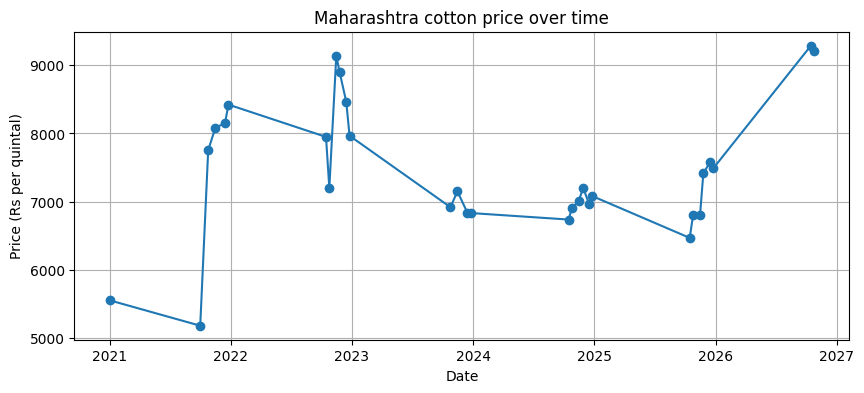

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["avg_modal_price"], marker="o")
plt.title("Maharashtra cotton price over time")
plt.xlabel("Date")
plt.ylabel("Price (Rs per quintal)")
plt.grid(True)
plt.show()

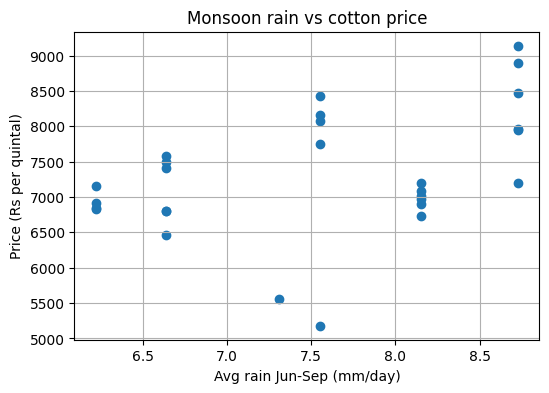

In [5]:
plt.figure(figsize=(6, 4))
plt.scatter(df["rain_jun_sep"], df["avg_modal_price"])
plt.title("Monsoon rain vs cotton price")
plt.xlabel("Avg rain Jun-Sep (mm/day)")
plt.ylabel("Price (Rs per quintal)")
plt.grid(True)
plt.show()

In [6]:
season_df = df.groupby("season").agg(
    avg_price=("avg_modal_price", "mean"),
    rain_jun_sep=("rain_jun_sep", "first"),
    yield_kg_per_ha=("yield_kg_per_ha", "first"),
    dates=("date", "count"),
).round(1)
season_df

,avg_price,rain_jun_sep,yield_kg_per_ha,dates
season,,,,
2020-21,5552.9,7.3,378.0,1
2021-22,7518.9,7.6,318.0,5
2022-23,8270.5,8.7,338.0,6
2023-24,6935.3,6.2,323.0,4
2024-25,6986.1,8.2,304.0,6
2025-26,7091.8,6.6,NaN,6
2026-27,9246.0,NaN,NaN,2


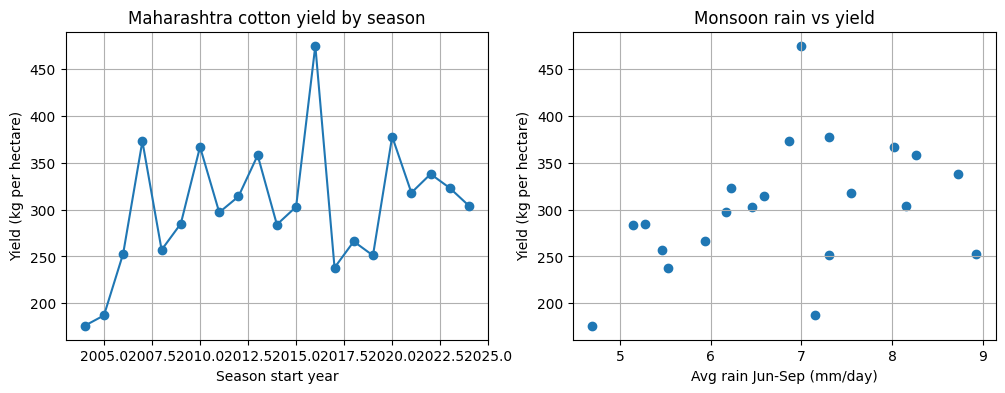

                 yield_kg_per_ha  rain_jun_sep  temp_jun_sep
yield_kg_per_ha             1.00          0.38         -0.26
rain_jun_sep                0.38          1.00         -0.50
temp_jun_sep               -0.26         -0.50          1.00


In [7]:
s = pd.read_csv("../data/processed/season_data.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Graph 1: yield over the years
ax[0].plot(s["start_year"], s["yield_kg_per_ha"], marker="o")
ax[0].set_title("Maharashtra cotton yield by season")
ax[0].set_xlabel("Season start year")
ax[0].set_ylabel("Yield (kg per hectare)")
ax[0].grid(True)

# Graph 2: monsoon rain vs yield
ax[1].scatter(s["rain_jun_sep"], s["yield_kg_per_ha"])
ax[1].set_title("Monsoon rain vs yield")
ax[1].set_xlabel("Avg rain Jun-Sep (mm/day)")
ax[1].set_ylabel("Yield (kg per hectare)")
ax[1].grid(True)

plt.show()

print(s[["yield_kg_per_ha", "rain_jun_sep", "temp_jun_sep"]].corr().round(2))

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import numpy as np

y = s["yield_kg_per_ha"].values

# Baseline: always guess the average of the other seasons
baseline = np.array([np.delete(y, i).mean() for i in range(len(y))])
print("Baseline error (MAE):", round(np.abs(y - baseline).mean(), 1))

for cols in (["rain_jun_sep"], ["rain_jun_sep", "temp_jun_sep"]):
    pred = cross_val_predict(LinearRegression(), s[cols], y, cv=LeaveOneOut())
    print(cols, "-> error (MAE):", round(np.abs(y - pred).mean(), 1))

Baseline error (MAE): 52.7
['rain_jun_sep'] -> error (MAE): 49.0
['rain_jun_sep', 'temp_jun_sep'] -> error (MAE): 51.3


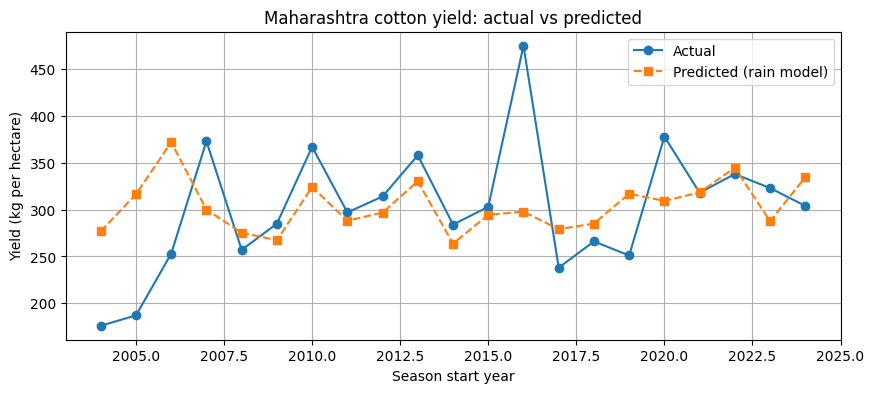

In [9]:
pred = cross_val_predict(LinearRegression(), s[["rain_jun_sep"]], y, cv=LeaveOneOut())

plt.figure(figsize=(10, 4))
plt.plot(s["start_year"], y, marker="o", label="Actual")
plt.plot(s["start_year"], pred, marker="s", linestyle="--", label="Predicted (rain model)")
plt.title("Maharashtra cotton yield: actual vs predicted")
plt.xlabel("Season start year")
plt.ylabel("Yield (kg per hectare)")
plt.legend()
plt.grid(True)
plt.show()


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression

s = pd.read_csv("../data/processed/season_data.csv")
model = LinearRegression().fit(s[["rain_jun_sep"]], s["yield_kg_per_ha"])

def predict_yield(rain_mm_per_day):
    p = model.predict(pd.DataFrame({"rain_jun_sep": [rain_mm_per_day]}))[0]
    return round(p), round(p - 49), round(p + 49)

for label, rain in [("Dry year", 5.0), ("Normal year", 6.8), ("Wet year", 8.5), ("Season 2025-26", 6.64)]:
    mid, low, high = predict_yield(rain)
    print(f"{label:15} rain {rain} -> about {mid} kg/ha (range {low} to {high})")

Dry year        rain 5.0 -> about 263 kg/ha (range 214 to 312)
Normal year     rain 6.8 -> about 302 kg/ha (range 253 to 351)
Wet year        rain 8.5 -> about 339 kg/ha (range 290 to 388)
Season 2025-26  rain 6.64 -> about 299 kg/ha (range 250 to 348)


In [10]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

price = pd.read_csv("../data/processed/maharashtra_price.csv", parse_dates=["date"])
world = pd.read_csv("../data/processed/world_cotton_price_monthly.csv", parse_dates=["date"])

# Match each price date with the world price of the same month
price["month"] = price["date"].dt.to_period("M").dt.to_timestamp()
world = world.rename(columns={"date": "month"})
pw = price.merge(world, on="month")

print("All 30 dates, correlation:",
      round(pw["avg_modal_price"].corr(pw["cotton_a_index_usd_per_kg"]), 2))

good = pw[pw["arrivals_tonnes"] >= 300].reset_index(drop=True)
print("Dates with arrivals >= 300 tonnes:", len(good), ", correlation:",
      round(good["avg_modal_price"].corr(good["cotton_a_index_usd_per_kg"]), 2))

# Honest test: hide one whole year at a time
years = good["date"].dt.year.values
y = good["avg_modal_price"].values
base = np.zeros(len(y))
for yr in set(years):
    base[years == yr] = y[years != yr].mean()
pred = cross_val_predict(LinearRegression(), good[["cotton_a_index_usd_per_kg"]], y,
                         cv=LeaveOneGroupOut(), groups=years)
print("Error if we guess the average:", round(np.abs(y - base).mean()))
print("Error using world price      :", round(np.abs(y - pred).mean()))

All 30 dates, correlation: 0.3
Dates with arrivals >= 300 tonnes: 20 , correlation: 0.57
Error if we guess the average: 757
Error using world price      : 802
